## Module 2 : Data Pre-processing

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np

# Path to the course file on Google Drive. Change it if you run the notebook elsewhere.
path = '/content/drive/MyDrive/SIB7 Bitlabs/midterm_hotel_data.csv'
df = pd.read_csv(path)

# Personal-data columns: not used in the analysis and never displayed
PII_COLS = [c for c in ["name", "email", "phone-number", "credit_card"] if c in df.columns]

df.drop(columns=PII_COLS).head()

,Unnamed: 0,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,0,Resort Hotel,0,342.0,2015,July,27,1,NaN,0,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0.0,Check-Out,2015-07-01
1,1,Resort Hotel,0,737.0,2015,July,27,1,0.0,0,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0.0,Check-Out,2015-07-01
2,2,Resort Hotel,0,7.0,2015,July,27,1,NaN,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,NaN,Check-Out,2015-07-02
3,3,Resort Hotel,0,13.0,2015,July,27,1,0.0,1,...,No Deposit,304.0,NaN,0,Transient,NaN,0,NaN,Check-Out,2015-07-02
4,4,Resort Hotel,0,NaN,2015,July,27,1,0.0,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,NaN,Check-Out,2015-07-03


In [3]:
# Data Summary before cleansing

duplicate_count = df.duplicated().sum()

inconsistent_data = {col: (df[col] < 0).sum() for col in df.select_dtypes(include=[np.number])}

missing_data = df.isnull().sum()

data_summary = pd.DataFrame({
    'Duplicate Data' : duplicate_count,
    'Inconsistent Values' : inconsistent_data,
    'Missing Data' : missing_data
})

print(data_summary)

# Extra check: duplicates when the personal-data and index columns are ignored
ignore_cols = [c for c in PII_COLS + ["Unnamed: 0"] if c in df.columns]
print("Duplicates ignoring personal-data and index columns:", df.drop(columns=ignore_cols).duplicated().sum())

                                Duplicate Data  Inconsistent Values  \
Unnamed: 0                                   0                  0.0   
adr                                          0                  1.0   
adults                                       0                  0.0   
agent                                        0                  0.0   
arrival_date_day_of_month                    0                  0.0   
arrival_date_month                           0                  NaN   
arrival_date_week_number                     0                  0.0   
arrival_date_year                            0                  0.0   
assigned_room_type                           0                  NaN   
babies                                       0                  0.0   
booking_changes                              0                  0.0   
children                                     0                  0.0   
company                                      0                  0.0   
countr

In [4]:
# Handle duplicates, inconsistent values, and missing values
initial_shape = df.shape
df_cleaned = df.drop_duplicates().copy()
removed_duplicates = initial_shape[0] - df_cleaned.shape[0]

num_columns = df_cleaned.select_dtypes(include=['float64', 'int64']).columns
cat_columns = df_cleaned.select_dtypes(include=['object']).columns

# Make sure numeric columns are numeric
for col in num_columns:
    df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='coerce')

# Negative values are inconsistent for this data: treat them as missing
for col in num_columns:
    df_cleaned.loc[df_cleaned[col] < 0, col] = np.nan

# Flag rows with a missing lead_time / adr BEFORE filling them,
# so analyses that depend on these columns can use observed values only
df_cleaned['lead_time_missing'] = df_cleaned['lead_time'].isna()
df_cleaned['adr_missing'] = df_cleaned['adr'].isna()
print("Rows with missing lead_time:", df_cleaned['lead_time_missing'].sum())
print("Rows with missing adr:", df_cleaned['adr_missing'].sum())

# Fill numeric columns with the median
for col in ['lead_time', 'stays_in_weekend_nights', 'adr']:
    df_cleaned[col] = df_cleaned[col].fillna(df_cleaned[col].median())

# Fill categorical columns with 'unknown'
for col in ['country', 'agent']:
    df_cleaned[col] = df_cleaned[col].fillna('unknown')

# Fill counts and company with 0
for col in ['total_of_special_requests', 'adults', 'children', 'company']:
    df_cleaned[col] = df_cleaned[col].fillna(0)

# Standardise text columns: trim spaces and lowercase
df_cleaned[cat_columns] = df_cleaned[cat_columns].apply(
    lambda x: x.str.strip().str.lower() if x.dtype == "object" else x
)

# Remove personal-data columns now that duplicates are handled (not used in the analysis)
df_cleaned = df_cleaned.drop(columns=PII_COLS)

# Check the result
df_cleaned.info(), removed_duplicates

Rows with missing lead_time: 35817
Rows with missing adr: 35818
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 35 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Unnamed: 0                      119390 non-null  float64
 1   hotel                           119390 non-null  object 
 2   is_canceled                     119390 non-null  float64
 3   lead_time                       119390 non-null  float64
 4   arrival_date_year               119390 non-null  float64
 5   arrival_date_month              119390 non-null  object 
 6   arrival_date_week_number        119390 non-null  float64
 7   arrival_date_day_of_month       119390 non-null  float64
 8   stays_in_weekend_nights         119390 non-null  float64
 9   stays_in_week_nights            119390 non-null  float64
 10  adults                          119390 non-null  float64
 11  children      

(None, 0)

In [5]:
df_cleaned.head()

,Unnamed: 0,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,lead_time_missing,adr_missing
0,0.0,resort hotel,0.0,342.0,2015.0,july,27.0,1.0,1.0,0.0,...,0.0,0.0,transient,0.0,0.0,0.0,check-out,2015-07-01,False,False
1,1.0,resort hotel,0.0,737.0,2015.0,july,27.0,1.0,0.0,0.0,...,0.0,0.0,transient,0.0,0.0,0.0,check-out,2015-07-01,False,False
2,2.0,resort hotel,0.0,7.0,2015.0,july,27.0,1.0,1.0,1.0,...,0.0,0.0,transient,75.0,0.0,0.0,check-out,2015-07-02,False,False
3,3.0,resort hotel,0.0,13.0,2015.0,july,27.0,1.0,0.0,1.0,...,0.0,0.0,transient,95.0,0.0,0.0,check-out,2015-07-02,False,True
4,4.0,resort hotel,0.0,69.0,2015.0,july,27.0,1.0,0.0,2.0,...,0.0,0.0,transient,98.0,0.0,0.0,check-out,2015-07-03,True,False


In [6]:
duplicate_count = df_cleaned.duplicated().sum()

missing_data = df_cleaned.isnull().sum()

inconsistent_data = {col: (df_cleaned[col] < 0).sum() for col in df_cleaned.select_dtypes(include=[np.number])}

data_summary_cleaned = pd.DataFrame({
    'Duplicate Data': [duplicate_count],
    'Inconsistent Values': [sum(inconsistent_data.values())],
    'Missing Data': [missing_data.sum()]
})

data_summary_cleaned

,Duplicate Data,Inconsistent Values,Missing Data
0,0,0,0


In [7]:
# Optional: save the cleaned data
df_cleaned.to_excel('dataset_cleaned.xlsx', index=False)

In [8]:
# Optional: save the cleaned data
df_cleaned.to_csv('dataset_cleaned.csv', index=False)

## Module 3 : SQL Query

In [9]:
!pip install -q pandasql
import pandasql as ps

df = df_cleaned

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


### 3.1

In [10]:
# Cancellation rate (%) for each hotel type, by arrival year

query = """SELECT hotel, arrival_date_year,
    ROUND(SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 1) AS cancellation_rate
FROM
    df
GROUP BY
    hotel, arrival_date_year
ORDER BY
    arrival_date_year, hotel
"""

#Execute the query
result = ps.sqldf(query, locals())
result

,hotel,arrival_date_year,cancellation_rate
0,city hotel,2015.0,43.9
1,resort hotel,2015.0,25.7
2,city hotel,2016.0,40.4
3,resort hotel,2016.0,26.6
4,city hotel,2017.0,42.5
5,resort hotel,2017.0,30.8


### 3.2

In [11]:
# Average lead time by number of special requests, only for bookings with above-average lead time (CTE for the overall average)
# Note: lead_time and adr include values filled with the median

query = """WITH avg_lead_time AS (
    SELECT AVG(lead_time) AS overall_avg_lead_time
    FROM df
)
SELECT
    total_of_special_requests,
    ROUND(AVG(lead_time), 2) AS average_lead_time
FROM
    df
WHERE
    lead_time > (SELECT overall_avg_lead_time FROM avg_lead_time)
GROUP BY
    total_of_special_requests
ORDER BY
    total_of_special_requests;
"""

#Execute the query
result = ps.sqldf(query, locals())
result

,total_of_special_requests,average_lead_time
0,0.0,210.77
1,1.0,190.41
2,2.0,182.47
3,3.0,181.80
4,4.0,197.04
5,5.0,171.55


### 3.3

In [12]:
# Date with the highest revenue proxy (sum of ADR): completed stays (check-out) with more than 2 special requests
# Note: lead_time and adr include values filled with the median

query = """
SELECT
    reservation_status_date,
    ROUND(SUM(adr), 2) AS total_revenue
FROM
    df
WHERE
    reservation_status = 'check-out'
    AND total_of_special_requests > 2
GROUP BY
    reservation_status_date
ORDER BY
    total_revenue DESC
LIMIT 1;
"""

#Execute the query
result = ps.sqldf(query, locals())
result

,reservation_status_date,total_revenue
0,2017-08-17,3036.86


### 3.4

In [13]:
# Average ADR by lead-time range (CTE with CASE WHEN buckets)
# Note: lead_time and adr include values filled with the median

query = """WITH lead_time_groups AS (
    SELECT
        CASE
            WHEN lead_time BETWEEN 0 AND 30 THEN '0-30 days'
            WHEN lead_time BETWEEN 31 AND 60 THEN '31-60 days'
            WHEN lead_time BETWEEN 61 AND 90 THEN '61-90 days'
            WHEN lead_time BETWEEN 91 AND 120 THEN '91-120 days'
            WHEN lead_time > 120 THEN '120+ days'
            ELSE 'Unknown'
        END AS lead_time_range,
        adr
    FROM
        df
)
SELECT
    lead_time_range,
    ROUND(AVG(adr), 2) AS average_adr
FROM
    lead_time_groups
GROUP BY
    lead_time_range
ORDER BY
    lead_time_range;
"""

#Execute the query
result = ps.sqldf(query, locals())
result

,lead_time_range,average_adr
0,0-30 days,97.65
1,120+ days,98.34
2,31-60 days,103.33
3,61-90 days,100.74
4,91-120 days,103.55


## Module 4 : Python EDA

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
df = df_cleaned

df.head()

,Unnamed: 0,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,lead_time_missing,adr_missing
0,0.0,resort hotel,0.0,342.0,2015.0,july,27.0,1.0,1.0,0.0,...,0.0,0.0,transient,0.0,0.0,0.0,check-out,2015-07-01,False,False
1,1.0,resort hotel,0.0,737.0,2015.0,july,27.0,1.0,0.0,0.0,...,0.0,0.0,transient,0.0,0.0,0.0,check-out,2015-07-01,False,False
2,2.0,resort hotel,0.0,7.0,2015.0,july,27.0,1.0,1.0,1.0,...,0.0,0.0,transient,75.0,0.0,0.0,check-out,2015-07-02,False,False
3,3.0,resort hotel,0.0,13.0,2015.0,july,27.0,1.0,0.0,1.0,...,0.0,0.0,transient,95.0,0.0,0.0,check-out,2015-07-02,False,True
4,4.0,resort hotel,0.0,69.0,2015.0,july,27.0,1.0,0.0,2.0,...,0.0,0.0,transient,98.0,0.0,0.0,check-out,2015-07-03,True,False


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 35 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Unnamed: 0                      119390 non-null  float64
 1   hotel                           119390 non-null  object 
 2   is_canceled                     119390 non-null  float64
 3   lead_time                       119390 non-null  float64
 4   arrival_date_year               119390 non-null  float64
 5   arrival_date_month              119390 non-null  object 
 6   arrival_date_week_number        119390 non-null  float64
 7   arrival_date_day_of_month       119390 non-null  float64
 8   stays_in_weekend_nights         119390 non-null  float64
 9   stays_in_week_nights            119390 non-null  float64
 10  adults                          119390 non-null  float64
 11  children                        119390 non-null  float64
 12  babies          

### 4.1

  lead_time_bucket  total_bookings  cancel_rate
0             0-30           27101         18.5
1            31-60           11844         36.9
2            61-90            8865         40.0
3           91-120            7238         44.6
4             121+           28525         52.2


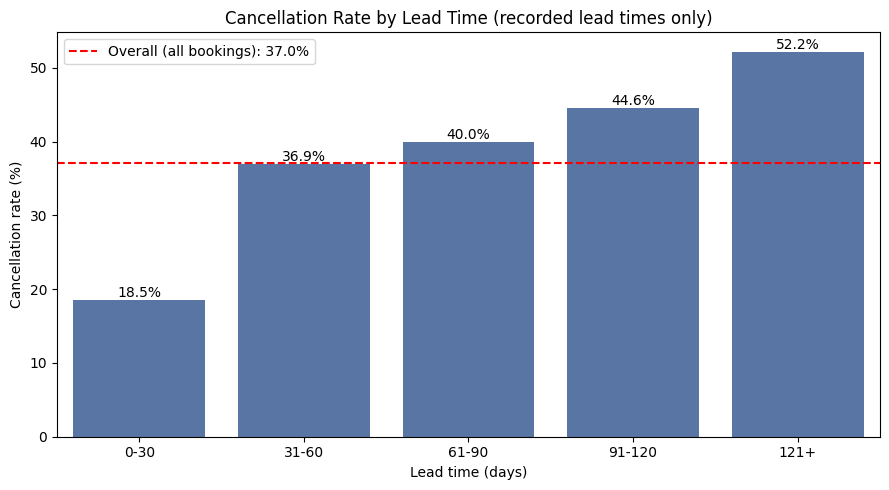

In [17]:
# Cancellation rate by lead-time bucket, using only bookings with a recorded lead time
observed = df[~df["lead_time_missing"]]

bucket = pd.cut(
    observed["lead_time"],
    bins=[-1, 30, 60, 90, 120, float("inf")],
    labels=["0-30", "31-60", "61-90", "91-120", "121+"]
)

lead_cancel = (
    observed.groupby(bucket, observed=True)["is_canceled"]
    .agg(total_bookings="size", cancel_rate=lambda s: s.mean() * 100)
    .round(1)
    .reset_index()
    .rename(columns={"lead_time": "lead_time_bucket"})
)
print(lead_cancel)

overall_rate = df["is_canceled"].mean() * 100

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=lead_cancel, x="lead_time_bucket", y="cancel_rate", color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.axhline(overall_rate, color="red", linestyle="--", label=f"Overall (all bookings): {overall_rate:.1f}%")
plt.title("Cancellation Rate by Lead Time (recorded lead times only)")
plt.xlabel("Lead time (days)")
plt.ylabel("Cancellation rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

### 4.2

In [18]:
# Average ADR per arrival month and hotel type (note: ADR includes values filled with the median)
month_order = ['january', 'february', 'march', 'april', 'may', 'june',
               'july', 'august', 'september', 'october', 'november', 'december']
df['arrival_date_month'] = pd.Categorical(df['arrival_date_month'], categories=month_order, ordered=True)

adr_by_hotel_month = df.groupby(['hotel', 'arrival_date_month'], observed=True)['adr'].mean().unstack(level=0)
adr_by_hotel_month

hotel,city hotel,resort hotel
arrival_date_month,,
january,86.729901,63.480848
february,87.962268,67.704737
march,92.904227,69.059359
april,106.583017,82.982103
may,113.713992,83.512442
june,112.160033,106.334309
july,106.294590,137.633910
august,108.852327,159.288572
september,105.425841,93.891014


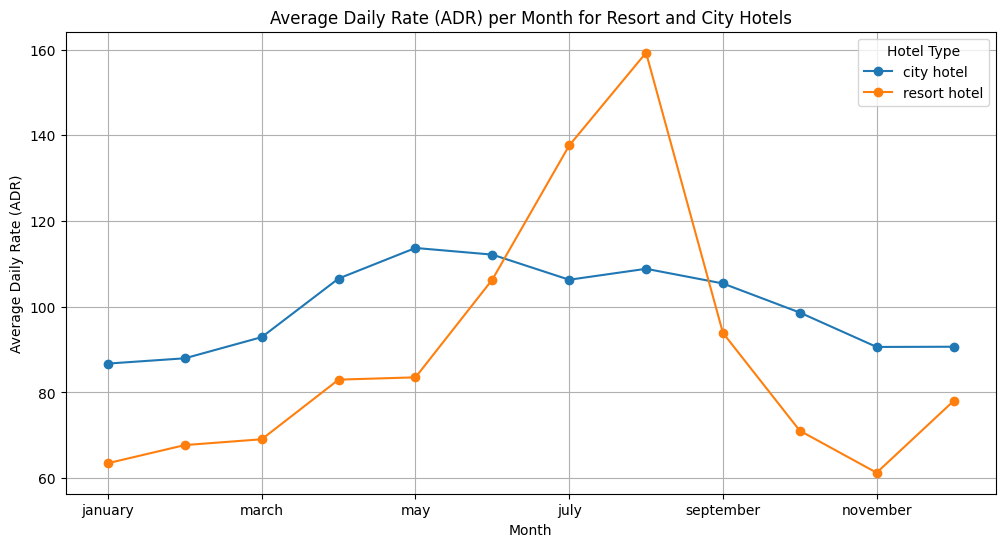

In [19]:
adr_by_hotel_month.plot(kind='line', marker='o', figsize=(12, 6))
plt.title('Average Daily Rate (ADR) per Month for Resort and City Hotels')
plt.xlabel('Month')
plt.ylabel('Average Daily Rate (ADR)')
plt.legend(title='Hotel Type')
plt.grid(True)
plt.show()

### 4.3

hotel    city hotel  resort hotel
country                          
prt            64.9          42.2
bra            40.6          23.5
ita            37.9          17.4
irl            33.1          19.9
esp            28.8          21.5
che            24.4          25.7
swe            21.4          24.0
gbr            29.4          13.1
pol            30.0          11.7
usa            26.5          15.0


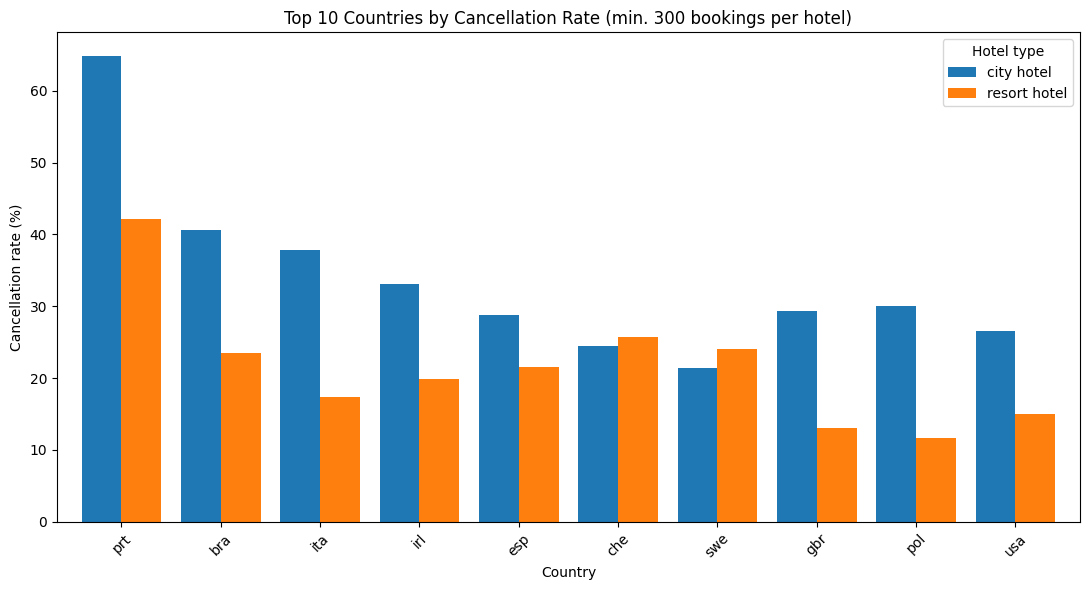

In [20]:
# Cancellation rate by country and hotel (min. 300 bookings per country-hotel pair)
country_hotel = (
    df[df["country"] != "unknown"]
    .groupby(["country", "hotel"])["is_canceled"]
    .agg(total="size", canceled="sum")
    .reset_index()
)
country_hotel = country_hotel[country_hotel["total"] >= 300].copy()
country_hotel["cancel_rate"] = country_hotel["canceled"] / country_hotel["total"] * 100

# Keep countries that pass the threshold in BOTH hotel types
pivot = country_hotel.pivot(index="country", columns="hotel", values="cancel_rate").dropna()
top10 = pivot.assign(avg=pivot.mean(axis=1)).nlargest(10, "avg").drop(columns="avg").round(1)
print(top10)

top10.plot(kind="bar", figsize=(11, 6), width=0.8)
plt.title("Top 10 Countries by Cancellation Rate (min. 300 bookings per hotel)")
plt.xlabel("Country")
plt.ylabel("Cancellation rate (%)")
plt.legend(title="Hotel type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.4

In [21]:
# Last-minute bookings = lead time under 7 days (counts, not shares)
last_minute = df[df['lead_time'] < 7]

last_minute_count_by_hoteltype = last_minute['hotel'].value_counts()
last_minute_count_by_month = last_minute['arrival_date_month'].value_counts()

In [22]:
last_minute_count_by_hoteltype


,count
hotel,
city hotel,7076
resort hotel,5810


In [23]:
last_minute_count_by_month

,count
arrival_date_month,
february,1519
january,1483
august,1328
march,1280
october,1026
december,987
may,975
april,933
november,931


/tmp/ipykernel_1336/3623675191.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=last_minute_count_by_hoteltype.index, y=last_minute_count_by_hoteltype.values, palette="viridis")


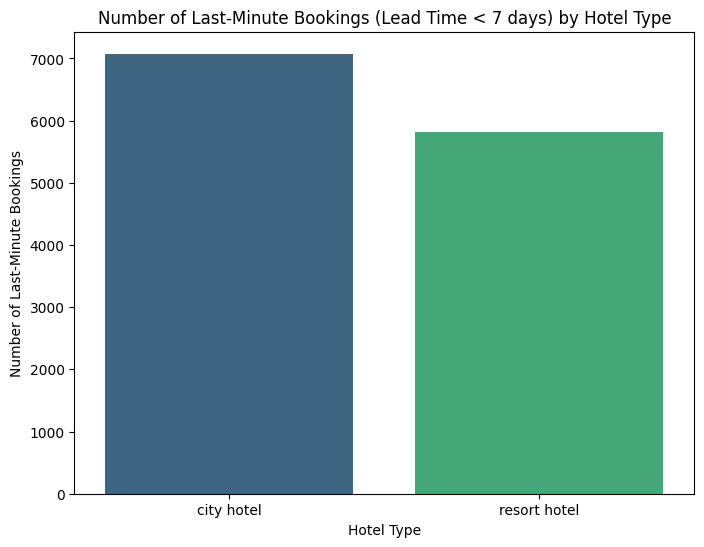

/tmp/ipykernel_1336/3623675191.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=last_minute_count_by_month.index, y=last_minute_count_by_month.values, palette="viridis")


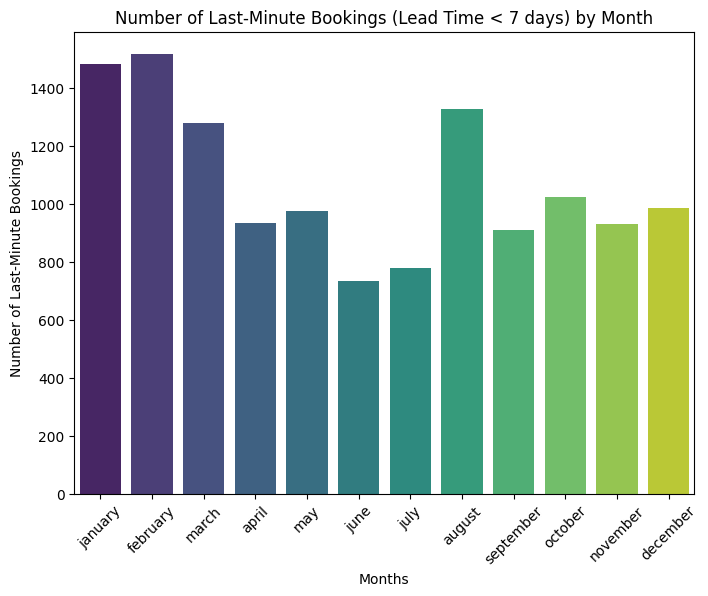

In [24]:
# Charts: last-minute bookings by hotel type and by month.
plt.figure(figsize=(8, 6))
sns.barplot(x=last_minute_count_by_hoteltype.index, y=last_minute_count_by_hoteltype.values, palette="viridis")
plt.title('Number of Last-Minute Bookings (Lead Time < 7 days) by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Last-Minute Bookings')
plt.show()

plt.figure(figsize=(8, 6))
sns.barplot(x=last_minute_count_by_month.index, y=last_minute_count_by_month.values, palette="viridis")
plt.title('Number of Last-Minute Bookings (Lead Time < 7 days) by Month')
plt.xlabel('Months')
plt.ylabel('Number of Last-Minute Bookings')
plt.xticks(rotation=45)
plt.show()

## Module 5 : A/B Testing

In [25]:
from scipy.stats import ttest_ind, mannwhitneyu, shapiro, levene

# Use only bookings with a recorded ADR above 0 (rows filled with the median are excluded)
valid_adr = ~df["adr_missing"] & (df["adr"] > 0)
city_hotel_adr = df.loc[(df["hotel"] == "city hotel") & valid_adr, "adr"]
resort_hotel_adr = df.loc[(df["hotel"] == "resort hotel") & valid_adr, "adr"]

# Step 1: normality check
shapiro_city = shapiro(city_hotel_adr)
shapiro_resort = shapiro(resort_hotel_adr)
print(f"Shapiro City Hotel   : p = {shapiro_city.pvalue:.3g}")
print(f"Shapiro Resort Hotel : p = {shapiro_resort.pvalue:.3g}")

# Step 2: choose the test based on normality and equal variances
if shapiro_city.pvalue > 0.05 and shapiro_resort.pvalue > 0.05:
    levene_test = levene(city_hotel_adr, resort_hotel_adr)
    if levene_test.pvalue > 0.05:
        t_test = ttest_ind(city_hotel_adr, resort_hotel_adr, equal_var=True)
        test_type = "Two-sample t-test with equal variances"
    else:
        t_test = ttest_ind(city_hotel_adr, resort_hotel_adr, equal_var=False)
        test_type = "Welch's t-test"
else:
    # At least one group is not normally distributed: use Mann-Whitney U
    t_test = mannwhitneyu(city_hotel_adr, resort_hotel_adr, alternative='two-sided')
    test_type = "Mann-Whitney U Test"

# Step 3: report p-value, medians, and effect size
p_text = "< 0.001" if t_test.pvalue < 0.001 else f"{t_test.pvalue:.3f}"
print(f"\nTest used: {test_type}")
print(f"p-value: {p_text}")
print(f"Median ADR  City: {city_hotel_adr.median():.2f} | Resort: {resort_hotel_adr.median():.2f}")

if test_type == "Mann-Whitney U Test":
    n1, n2 = len(city_hotel_adr), len(resort_hotel_adr)
    rank_biserial = 2 * t_test.statistic / (n1 * n2) - 1   # > 0: City Hotel ADR tends to be higher
    print(f"Effect size (rank-biserial): {rank_biserial:.2f}")

if t_test.pvalue < 0.05:
    print("\nConclusion: reject H0. ADR distributions differ significantly between City Hotel and Resort Hotel.")
else:
    print("\nConclusion: fail to reject H0. No significant ADR difference between City Hotel and Resort Hotel.")

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 54645.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 27556.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro City Hotel   : p = 8.52e-90
Shapiro Resort Hotel : p = 1.41e-88

Test used: Mann-Whitney U Test
p-value: < 0.001
Median ADR  City: 100.00 | Resort: 76.95
Effect size (rank-biserial): 0.27

Conclusion: reject H0. ADR distributions differ significantly between City Hotel and Resort Hotel.


In [26]:
## Robustness check: without identical rows
## Repeats the key results after removing rows that are identical in all booking attributes.

dedup = df.drop(columns=["Unnamed: 0"], errors="ignore").drop_duplicates()
print("Rows:", len(df), "->", len(dedup), "| removed:", len(df) - len(dedup))
print("Overall cancellation rate: %.1f%%" % (dedup["is_canceled"].mean() * 100))

# 1) Cancellation rate by lead time (recorded lead times only)
obs = dedup[~dedup["lead_time_missing"]]
bucket = pd.cut(obs["lead_time"], bins=[-1, 30, 60, 90, 120, float("inf")],
                labels=["0-30", "31-60", "61-90", "91-120", "121+"])
print(obs.groupby(bucket, observed=True)["is_canceled"]
         .agg(total="size", cancel_rate=lambda s: s.mean() * 100).round(1))

# 2) ADR: City Hotel vs Resort Hotel (recorded ADR above 0 only)
valid = dedup[~dedup["adr_missing"] & (dedup["adr"] > 0)]
city = valid.loc[valid["hotel"] == "city hotel", "adr"]
resort = valid.loc[valid["hotel"] == "resort hotel", "adr"]
u, p = mannwhitneyu(city, resort, alternative="two-sided")
print("Median ADR  City:", city.median(), "| Resort:", resort.median())
print("p-value:", "< 0.001" if p < 0.001 else round(p, 3),
      "| rank-biserial:", round(2 * u / (len(city) * len(resort)) - 1, 2))

# 3) Top 5 countries by cancellation rate (min. 300 bookings per hotel)
ch = (dedup[dedup["country"] != "unknown"]
      .groupby(["country", "hotel"])["is_canceled"]
      .agg(total="size", canceled="sum").reset_index())
ch = ch[ch["total"] >= 300].copy()
ch["cancel_rate"] = ch["canceled"] / ch["total"] * 100
pv = ch.pivot(index="country", columns="hotel", values="cancel_rate").dropna()
print(pv.assign(avg=pv.mean(axis=1)).nlargest(5, "avg").drop(columns="avg").round(1))

Rows: 119390 -> 104303 | removed: 15087
Overall cancellation rate: 31.6%
           total  cancel_rate
lead_time                    
0-30       26137         17.4
31-60      10572         33.3
61-90       7683         35.3
91-120      6049         38.0
121+       21381         43.5
Median ADR  City: 103.5 | Resort: 78.935
p-value: < 0.001 | rank-biserial: 0.27
hotel    city hotel  resort hotel
country                          
prt            51.9          38.6
bra            40.8          23.6
ita            37.6          17.7
irl            32.2          18.8
esp            29.2          21.4
